<a href="https://colab.research.google.com/github/c-sruthi67/biomedical-ml-portfolio/blob/01-diabetes-risk/diabetes_risk_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Diabetes from CDC BRFSS Health Indicators

Comparing logistic regression and random forest models, tuned for high recall in screening.

Data: CDC Diabetes Health Indicators (BRFSS 2015), UCI Machine Learning Repository.
https://doi.org/10.24432/C53919


In [1]:
# PRELIMINARY: Install Required Packages
# ucimlrepo loads datasets directly from the UCI ML Repository.
# Colab already includes pandas and scikit-learn.
# Rerun this cell whenever the Colab runtime restarts.

!pip install ucimlrepo

In [2]:
# STEP 1: Load the Dataset

from ucimlrepo import fetch_ucirepo

# Download the CDC Diabetes Health Indicators dataset (UCI id 891)
cdc_diabetes_health_indicators = fetch_ucirepo(id=891)

# Split into features and target (both are pandas DataFrames)
X = cdc_diabetes_health_indicators.data.features  # 21 columns
y = cdc_diabetes_health_indicators.data.targets   # 1 column, 2 results: 0/1

# Metadata (dataset description)
print(cdc_diabetes_health_indicators.metadata)

# Each variable is defined by the information it gives and how it is coded
print(cdc_diabetes_health_indicators.variables)

{'uci_id': 891, 'name': 'CDC Diabetes Health Indicators', 'repository_url': 'https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators', 'data_url': 'https://archive.ics.uci.edu/static/public/891/data.csv', 'abstract': 'The Diabetes Health Indicators Dataset contains healthcare statistics and lifestyle survey information about people in general along with their diagnosis of diabetes. The 35 features consist of some demographics, lab test results, and answers to survey questions for each patient. The target variable for classification is whether a patient has diabetes, is pre-diabetic, or healthy. ', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Tabular', 'Multivariate'], 'num_instances': 253680, 'num_features': 21, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Sex', 'Age', 'Education Level', 'Income'], 'target_col': ['Diabetes_binary'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_

In [3]:
# STEP 2: Explore the Data

print(X.shape)                        # (rows, columns)
print(X.head())                       # first 5 rows shown

print(X.columns.tolist())             # every column name is shown

print(y.value_counts())               # counts of 0s and 1s are shown
print(y.value_counts(normalize=True)) # data is 13.93% diabetic (imbalanced)

(253680, 21)
   HighBP  HighChol  CholCheck  BMI  Smoker  Stroke  HeartDiseaseorAttack  \
0       1         1          1   40       1       0                     0   
1       0         0          0   25       1       0                     0   
2       1         1          1   28       0       0                     0   
3       1         0          1   27       0       0                     0   
4       1         1          1   24       0       0                     0   

   PhysActivity  Fruits  Veggies  ...  AnyHealthcare  NoDocbcCost  GenHlth  \
0             0       0        1  ...              1            0        5   
1             1       0        0  ...              0            1        3   
2             0       1        0  ...              1            1        5   
3             1       1        1  ...              1            0        2   
4             1       1        1  ...              1            0        2   

   MentHlth  PhysHlth  DiffWalk  Sex  Age  Education  I

In [4]:
# STEP 3: Preprocessing - Split Into Training and Testing Sets

from sklearn.model_selection import train_test_split

# Converts y from 1-column DataFrame -> simple 1D array
# Note: running this line twice produces an error:
#       use Runtime -> Run before to reset
y = y.values.ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,   # hold 25% as unseen test data
    stratify=y,       # keep same 13.93% diabetic rate in both sets
    random_state=35   # ensure reproducible results
)

print(X_train.shape, X_test.shape)    # size of each set
print(y_train.mean(), y_test.mean())  # mean of 0/1 = fraction of
                                      # diabetic patients should be ~ 0.1393

(190260, 21) (63420, 21)
0.13933038999264163 0.13934090192368337


In [5]:
# STEP 4: Preprocessing - Scaling Method
#         Model 1 - Logistic Regression

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# Scale features to mean=0 and std=1 so large-range columns (eg. BMI)
# don't dominate
# fit_transform on training data: learn the mean/std AND rescale
# Transform only on test data: reuse the training mean/std to avoid data leakage
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Penalizes missed diabetics ~6x more,
# offsetting the imbalance (~6 healthy people per diabetic)
model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train_s, y_train) # train on scaled training data only;
                              # the test set stays unseen until evaluation

# 0/1 predictions at the default 0.5 threshold
y_pred = model.predict(X_test_s)

# Precision, recall, and F1 for each class
# Class 1 recall is the key metric!
print(classification_report(y_test, y_pred))

# ROC-AUC uses predicted probabilities, not 0/1 labels -> it doesn't depend on
# the threshold
print("ROC-AUC:", roc_auc_score(y_test, model.predict_proba(X_test_s)[:, 1]))

              precision    recall  f1-score   support

           0       0.95      0.73      0.82     54583
           1       0.31      0.76      0.44      8837

    accuracy                           0.73     63420
   macro avg       0.63      0.75      0.63     63420
weighted avg       0.86      0.73      0.77     63420

ROC-AUC: 0.8194697465836481


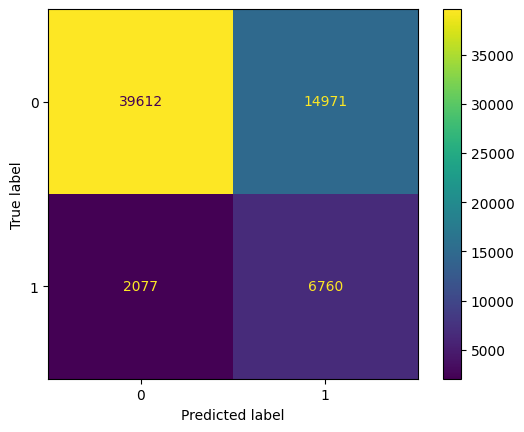

In [6]:
# STEP 5: Confusion Matrix for Logistic Regression
# How to read: rows = true label, column = predicted label
#              top-left: true negatives,
#              top-right: false positives (false alarm),
#              bottom-left: false negatives (missed diabetics),
#              bottom-right: true positives.

from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, values_format='d')

In [7]:
# STEP 6: Model 2a - Random Forest with Default Settings
# Takes 1-2 min to run.
# Default trees grow until each leaf is pure, which memorizes the
# training data (overfitting).
# Result: high accuracy but very low class 1 recall (~0.16).

from sklearn.ensemble import RandomForestClassifier

rf_default = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    n_jobs=-1,
    random_state=35
)
rf_default.fit(X_train, y_train) # note: unscaled data

rf_default_pred = rf_default.predict(X_test)
print(classification_report(y_test, rf_default_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_default.predict_proba(X_test)[:, 1]))

              precision    recall  f1-score   support

           0       0.88      0.97      0.92     54583
           1       0.46      0.16      0.24      8837

    accuracy                           0.86     63420
   macro avg       0.67      0.56      0.58     63420
weighted avg       0.82      0.86      0.83     63420

ROC-AUC: 0.7953829430208466


In [8]:
# STEP 7: Model 2b - Random Forest with min_samples_leaf=50
# Takes 1-2 min to run.
# Trees stop splitting once a split would leave fewer than 50 people in a leaf;
# this rule limits memorization of the training data (reduces overfitting).
# Result: class 1 recall ~0.78, ROC-AUC ~0.83
# Note: too large a value causes underfitting; compare several values
#       (eg. 10, 50, 200) on a validation set to choose the best.

rf = RandomForestClassifier(
    n_estimators=100,         # number of trees that vote on each prediction
    min_samples_leaf=50,      # each leaf must hold >= 50 people to reduce overfitting
    class_weight='balanced',  # extra weight on the rare diabetic class
    n_jobs=-1,                # use all CPU cores to train faster
    random_state=35           # ensure reproducible results
)

# Unscaled data is fine to use here because trees split on thresholds:
# so the scale of a feature doesn't change which split is best
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
print(classification_report(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]))

              precision    recall  f1-score   support

           0       0.95      0.72      0.82     54583
           1       0.31      0.78      0.44      8837

    accuracy                           0.73     63420
   macro avg       0.63      0.75      0.63     63420
weighted avg       0.86      0.73      0.77     63420

ROC-AUC: 0.8253425592099808


In [9]:
# STEP 8: Threshold Tuning Decision Step
# predict() flags someone only if their probability >= 0.5.
# Lowering the threshold flags more patients -> recall rises, precision falls.
# Note: choosing the threshold on the test set is a limitation:
#       ideally it would be chosen on a separate validation set.

from sklearn.metrics import recall_score, precision_score

probs = rf.predict_proba(X_test)[:, 1] # each patient's predicted prob. of diabetes

for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (probs >= t).astype(int) # 1 if prob. >= threshold, else 0

    print(f"threshold {t}: recall={recall_score(y_test, pred_t):.2f}, "
          f"precision={precision_score(y_test, pred_t):.2f}")

# Chosen threshold for screening: 0.3 (recall ~0.93, precision ~0.23)

threshold 0.3: recall=0.93, precision=0.23
threshold 0.4: recall=0.87, precision=0.27
threshold 0.5: recall=0.78, precision=0.31
threshold 0.6: recall=0.64, precision=0.36
threshold 0.7: recall=0.46, precision=0.43


<Axes: >

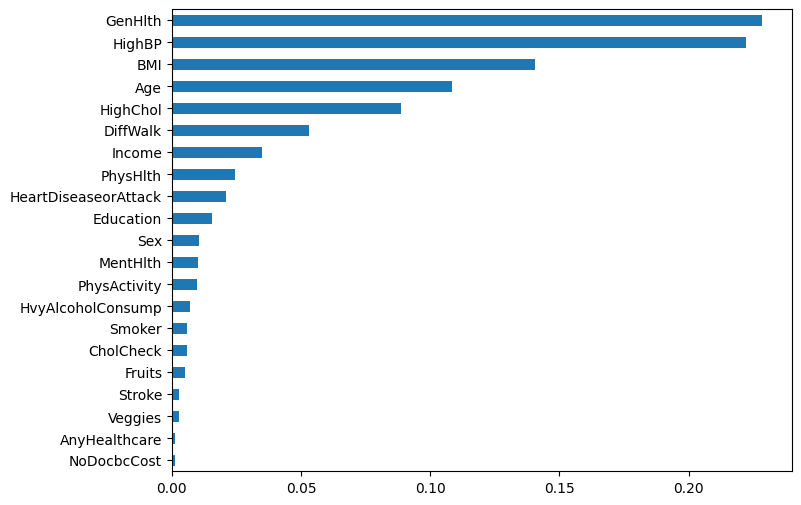

In [10]:
# STEP 9: Learn What Drives Predictions via Feature Importance
# Measures how much each feature's splits separate diabetics from
# non-diabetics, summed over all trees and scaled to add up to 1.
# Note: Importance ≠ causation.
#       Features with many values (eg. BMI, Age) can get inflated scores.
import pandas as pd

importances = pd.Series(rf.feature_importances_, index=X.columns)
importances.sort_values().plot(kind='barh', figsize=(8, 6)) # horizontal bar chart